In [1]:
# ---- 0. Data: run this cell, click "Choose files" and select  xbd_crops_vit.zip  (one file, ~290 MB) ----
import os, csv, glob, zipfile, shutil

DATA_ROOT = "/content/xbd_crops_vit"        # the rest of the notebook reads DATA_ROOT/metadata.csv and DATA_ROOT/crops/
META, CROPS = f"{DATA_ROOT}/metadata.csv", f"{DATA_ROOT}/crops"

def _missing_files():
    """None if metadata.csv is not there yet, else the crop files listed in it that are not on disk."""
    if not os.path.exists(META): return None
    with open(META, newline="") as f:
        need = {r[k] for r in csv.DictReader(f) for k in ("filename_pre", "filename_post")}
    have = set(os.listdir(CROPS)) if os.path.isdir(CROPS) else set()
    return need - have

def _extract(zip_path):
    os.makedirs(DATA_ROOT, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_ROOT)                              # zip has metadata.csv + crops/ at its root
    wrapper = f"{DATA_ROOT}/xbd_crops_vit"                   # tolerate a zip that has a wrapper folder
    if os.path.isdir(wrapper):
        shutil.copytree(wrapper, DATA_ROOT, dirs_exist_ok=True); shutil.rmtree(wrapper)

if _missing_files() != set():                                # not extracted yet (or incomplete)
    zips = sorted(glob.glob("/content/xbd_crops_vit*.zip"))  # e.g. already dragged into the Files sidebar
    if not zips:
        from google.colab import files
        print("Choose xbd_crops_vit.zip ...")
        files.upload()                                       # <- the only thing you need to do
        zips = sorted(glob.glob("/content/xbd_crops_vit*.zip"))
    assert zips, "No xbd_crops_vit zip was received - run this cell again and choose xbd_crops_vit.zip"
    for p in zips:
        if not zipfile.is_zipfile(p):                        # a cut-off upload has no valid zip directory
            got = os.path.getsize(p) / 1e6
            os.remove(p)
            raise AssertionError(f"{os.path.basename(p)} was only partly uploaded ({got:.0f} MB received). "
                                 "Just run this cell again and upload it once more (keep the browser tab open until it finishes).")
        print("Extracting", os.path.basename(p), "...")
        _extract(p)

miss = _missing_files()
assert miss is not None, "metadata.csv not found - make sure you uploaded xbd_crops_vit.zip"
assert not miss, f"{len(miss):,} crop files listed in metadata.csv are missing - run this cell again and re-upload xbd_crops_vit.zip"
print(f"Dataset OK: {DATA_ROOT} | {len(os.listdir(CROPS)):,} crop files, all matched to metadata.csv")


Choose xbd_crops_vit.zip ...


Saving xbd_crops_vit.zip to xbd_crops_vit.zip
Extracting xbd_crops_vit.zip ...
Dataset OK: /content/xbd_crops_vit | 164,736 crop files, all matched to metadata.csv


In [2]:
!pip install -q -U timm folium

In [3]:
import os, io, math, time, copy, base64, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as mcm
from PIL import Image
from tqdm.auto import tqdm
from scipy.stats import spearmanr

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, cohen_kappa_score, accuracy_score

SEED = 43
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
assert DEVICE.type == "cuda", "No GPU found: Runtime > Change runtime type > T4 GPU, then Run all again."
print("Device:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| timm", timm.__version__)

CLASS_MAP = {"no-damage": 0, "minor-damage": 1, "major-damage": 2, "destroyed": 3}
IDX_TO_CLASS = {v: k for k, v in CLASS_MAP.items()}
NUM_CLASSES = 4

Device: Tesla T4 | torch 2.11.0+cu130 | timm 1.0.30


In [4]:
CFG = dict(
    backbone      = "vit_small_patch14_dinov2.lvd142m",                    # DINOv2 ViT-S/14
    fallback_bb   = "vit_small_patch16_224.augreg_in21k_ft_in1k",          # used only if the DINOv2 download fails
    img_size      = 224,
    batch_size    = 64,
    epochs        = 6,
    freeze_blocks = 4,        # of 12 transformer blocks (+ patch/pos embedding) kept frozen
    base_lr       = 2e-4,     # LR of the last backbone block
    layer_decay   = 0.75,     # LR multiplier per block going down the network (layer-wise LR decay)
    head_lr       = 1e-3,     # LR of the new modules (fusion + heads)
    weight_decay  = 0.05,
    dropout       = 0.2,
    focal_gamma   = 2.0,
    lambda_ord    = 0.5,      # ordinal (EMD) loss weight
    lambda_prio   = 5.0,      # priority-regression loss weight
    num_workers   = min(4, os.cpu_count() or 2),
)
UNSEEN_DISASTER = "hurricane-michael"

# Priority POLICY (editable by emergency planners): how much each factor contributes to urgency
W_DAMAGE, W_DENSITY, W_AREA = 0.60, 0.25, 0.15

In [5]:
# ---- Metadata, priority target, disaster-level hold-out, scene-level train/val/test split ----
CROPS_DIR = f"{DATA_ROOT}/crops"
df = pd.read_csv(f"{DATA_ROOT}/metadata.csv")
print(f"Total crops: {len(df):,} | disasters: {df.disaster_type.nunique()}")
print(df["label_name"].value_counts().to_dict())

def minmax(x): return (x - x.min()) / (x.max() - x.min() + 1e-9)
df["pixel_area"] = df["pixel_area"].fillna(df["pixel_area"].median())
df["density_norm"] = minmax(np.log1p(df.groupby("scene_id")["uid"].transform("count")))                 # buildings in the same scene
df["area_norm"] = minmax(np.log1p(df["pixel_area"].clip(upper=df["pixel_area"].quantile(0.99))))        # footprint size
# policy target (uses ground-truth damage; used ONLY to train/evaluate the priority head)
df["priority_target"] = W_DAMAGE * df["label"] / (NUM_CLASSES - 1) + W_DENSITY * df["density_norm"] + W_AREA * df["area_norm"]

seen_df   = df[df.disaster_type != UNSEEN_DISASTER].reset_index(drop=True)
unseen_df = df[df.disaster_type == UNSEEN_DISASTER].reset_index(drop=True)
assert len(unseen_df) > 0, f"'{UNSEEN_DISASTER}' not in metadata. Available: {sorted(df.disaster_type.unique())}"

def strat(col): return col if col.value_counts().min() >= 2 else None
scenes = seen_df.drop_duplicates("scene_id")[["scene_id", "disaster_type"]]       # split by SCENE: no leakage between splits
train_sc, rest_sc = train_test_split(scenes, test_size=0.3, stratify=strat(scenes["disaster_type"]), random_state=SEED)
val_sc, test_sc   = train_test_split(rest_sc, test_size=0.5, stratify=strat(rest_sc["disaster_type"]), random_state=SEED)
train_df = seen_df[seen_df.scene_id.isin(train_sc.scene_id)].reset_index(drop=True)
val_df   = seen_df[seen_df.scene_id.isin(val_sc.scene_id)].reset_index(drop=True)
test_df  = seen_df[seen_df.scene_id.isin(test_sc.scene_id)].reset_index(drop=True)
print(f"train={len(train_df):,}  val={len(val_df):,}  test(seen)={len(test_df):,}  unseen({UNSEEN_DISASTER})={len(unseen_df):,}")

cc = train_df["label"].value_counts().reindex(range(NUM_CLASSES)).fillna(1)
class_weights = torch.tensor(1.0 / cc.values, dtype=torch.float32)
class_weights = (class_weights / class_weights.sum() * NUM_CLASSES).to(DEVICE)
print("Class weights:", class_weights.cpu().numpy().round(3))

Total crops: 82,368 | disasters: 10
{'no-damage': 40000, 'minor-damage': 14980, 'major-damage': 14161, 'destroyed': 13227}
train=50,556  val=9,665  test(seen)=9,297  unseen(hurricane-michael)=12,850
Class weights: [0.401 1.471 1.088 1.04 ]


In [6]:
# ---- Dataset: pair-consistent augmentation (same crop/flip/rotation for pre and post) ----
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class BuildingDamageDataset(Dataset):
    def __init__(self, dataframe, img_size, train=False):
        self.df, self.size, self.train = dataframe.reset_index(drop=True), img_size, train
        self.pre, self.post = self.df["filename_pre"].values, self.df["filename_post"].values
        self.y   = self.df["label"].values.astype(np.int64)
        self.ctx = self.df[["density_norm", "area_norm"]].values.astype(np.float32)
        self.tgt = self.df["priority_target"].values.astype(np.float32)
        self.cj = T.ColorJitter(0.15, 0.15, 0.1)            # applied independently: real pre/post radiometric differences
        self.norm = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

    def __len__(self): return len(self.df)

    def _geo(self, pre, post):
        w, h = pre.size
        s = random.uniform(0.75, 1.0)
        cw, ch = int(w * s), int(h * s)
        x, y = random.randint(0, w - cw), random.randint(0, h - ch)
        pre  = TF.resized_crop(pre,  y, x, ch, cw, [self.size, self.size])
        post = TF.resized_crop(post, y, x, ch, cw, [self.size, self.size])
        if random.random() < 0.5: pre, post = TF.hflip(pre), TF.hflip(post)
        if random.random() < 0.5: pre, post = TF.vflip(pre), TF.vflip(post)
        k = random.randint(0, 3)
        if k: pre, post = pre.rotate(90 * k), post.rotate(90 * k)
        return pre, post

    def __getitem__(self, i):
        pre  = Image.open(f"{CROPS_DIR}/{self.pre[i]}").convert("RGB")
        post = Image.open(f"{CROPS_DIR}/{self.post[i]}").convert("RGB")
        if self.train:
            pre, post = self.cj(pre), self.cj(post)          # on the small 96px crop (cheap), then resize to model size
            pre, post = self._geo(pre, post)
        else:
            pre, post = pre.resize((self.size, self.size), Image.BICUBIC), post.resize((self.size, self.size), Image.BICUBIC)
        return self.norm(pre), self.norm(post), int(self.y[i]), torch.from_numpy(self.ctx[i]), float(self.tgt[i])

def make_loader(d, train):
    nw = CFG["num_workers"]
    return DataLoader(BuildingDamageDataset(d, CFG["img_size"], train), batch_size=CFG["batch_size"], shuffle=train, drop_last=train,
                      num_workers=nw, pin_memory=USE_AMP, persistent_workers=nw > 0, **({"prefetch_factor": 4} if nw > 0 else {}))

In [7]:
# ---- Model: partially-frozen Siamese ViT + Cross-Temporal Change Attention + damage head + priority head ----
class Attn(nn.Module):
    """Multi-head attention (queries attend to keys/values) via scaled_dot_product_attention; safe under fp16 autocast."""
    def __init__(self, d, heads):
        super().__init__()
        self.h, self.q, self.kv, self.o = heads, nn.Linear(d, d), nn.Linear(d, 2 * d), nn.Linear(d, d)
    def forward(self, q, kv):
        B, Nq, D = q.shape; Nk = kv.shape[1]
        Q = self.q(q).view(B, Nq, self.h, -1).transpose(1, 2)
        K, V = self.kv(kv).view(B, Nk, 2, self.h, -1).permute(2, 0, 3, 1, 4)
        return self.o(F.scaled_dot_product_attention(Q, K, V).transpose(1, 2).reshape(B, Nq, D))

class RefineBlock(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.n1, self.n2, self.att = nn.LayerNorm(d), nn.LayerNorm(d), Attn(d, heads)
        self.mlp = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
    def forward(self, x):
        h = self.n1(x); x = x + self.att(h, h)
        return x + self.mlp(self.n2(x))

class CrossTemporalChangeAttention(nn.Module):
    """Post-image patch tokens query the pre-image patch tokens ("what in the BEFORE image matches this AFTER patch?").
    Residual + raw difference form change tokens, one transformer block refines them, a learned query pools them."""
    def __init__(self, d, heads):
        super().__init__()
        self.ln_pre, self.ln_post, self.align = nn.LayerNorm(d), nn.LayerNorm(d), Attn(d, heads)
        self.mix = nn.Sequential(nn.Linear(2 * d, d), nn.GELU(), nn.LayerNorm(d))
        self.refine, self.pool, self.ln_out = RefineBlock(d, heads), Attn(d, heads), nn.LayerNorm(d)
        self.query = nn.Parameter(torch.randn(1, 1, d) * 0.02)
    def forward(self, tp, tq):
        kv = self.ln_pre(tp)
        aligned = self.align(self.ln_post(tq), kv)
        change = self.refine(self.mix(torch.cat([tq - aligned, tq - tp], dim=-1)))
        return self.ln_out(self.pool(self.query.expand(tp.size(0), -1, -1), change).squeeze(1))

class DamageNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        try:
            self.vit = timm.create_model(cfg["backbone"], pretrained=True, num_classes=0, img_size=cfg["img_size"])
        except Exception as e:
            print(f"[warn] could not load {cfg['backbone']} ({type(e).__name__}); using {cfg['fallback_bb']}")
            self.vit = timm.create_model(cfg["fallback_bb"], pretrained=True, num_classes=0, img_size=cfg["img_size"])
        d, self.npt, self.k = self.vit.num_features, self.vit.num_prefix_tokens, cfg["freeze_blocks"]

        # FREEZE: patch embedding, position embedding, class token, first k transformer blocks
        for mod in [self.vit.patch_embed] + list(self.vit.blocks[:self.k]):
            for p in mod.parameters(): p.requires_grad = False
        for n in ("cls_token", "pos_embed", "reg_token"):
            if getattr(self.vit, n, None) is not None: getattr(self.vit, n).requires_grad = False

        heads = 6 if d % 6 == 0 else 8
        self.fusion = CrossTemporalChangeAttention(d, heads)
        in_dim = 4 * d                                                       # [cls_pre, cls_post, |diff|, change vector]
        self.head = nn.Sequential(nn.Linear(in_dim, 512), nn.BatchNorm1d(512), nn.GELU(), nn.Dropout(cfg["dropout"]),
                                  nn.Linear(512, 128), nn.BatchNorm1d(128), nn.GELU(), nn.Linear(128, NUM_CLASSES))
        self.prio_head = nn.Sequential(nn.Linear(in_dim + 2, 256), nn.GELU(), nn.Dropout(cfg["dropout"]),
                                       nn.Linear(256, 64), nn.GELU(), nn.Linear(64, 1))   # image features + (density, area) -> urgency

    def forward(self, pre, post, ctx):
        B = pre.size(0)
        tok = self.vit.forward_features(torch.cat([pre, post], 0))         # shared weights (Siamese), one pass
        tp, tq = tok[:B], tok[B:]
        cls_p, cls_q = tp[:, 0], tq[:, 0]
        feats = [cls_p, cls_q, (cls_p - cls_q).abs(), self.fusion(tp[:, self.npt:], tq[:, self.npt:])]
        z = torch.cat([f.float() for f in feats], 1)
        return self.head(z), torch.sigmoid(self.prio_head(torch.cat([z, ctx.float()], 1))).squeeze(1)

    def param_groups(self):
        """Layer-wise LR decay: last block gets base_lr, each earlier trainable block is multiplied by layer_decay."""
        cfg, L, groups = self.cfg, len(self.vit.blocks), []
        for i in range(self.k, L):
            groups.append(dict(params=list(self.vit.blocks[i].parameters()), lr=cfg["base_lr"] * cfg["layer_decay"] ** (L - 1 - i)))
        groups.append(dict(params=list(self.vit.norm.parameters()), lr=cfg["base_lr"]))
        new = [self.fusion, self.head, self.prio_head]
        groups.append(dict(params=[p for m in new for p in m.parameters()], lr=cfg["head_lr"]))
        for g in groups: g["base"] = g["lr"]
        return groups

class DamageLoss(nn.Module):
    """class-weighted focal loss + squared-EMD ordinal penalty (confusing 'minor' with 'destroyed' costs more than with 'major')"""
    def __init__(self, weight, gamma, lam_ord):
        super().__init__(); self.w, self.g, self.lo = weight, gamma, lam_ord
    def forward(self, logits, y):
        ce = F.cross_entropy(logits.float(), y, weight=self.w, reduction="none")
        focal = (((1 - torch.exp(-ce)) ** self.g) * ce).mean()
        p = logits.float().softmax(1)
        emd = ((p.cumsum(1) - F.one_hot(y, NUM_CLASSES).float().cumsum(1)) ** 2).sum(1).mean()
        return focal + self.lo * emd

In [8]:
# ---- Training / evaluation helpers ----
def topk_overlap(score, tgt, frac=0.10):
    k = max(1, int(frac * len(tgt)))
    return len(set(np.argsort(-score)[:k]) & set(np.argsort(-tgt)[:k])) / k

def metrics(o):
    pred, y = o["probs"].argmax(1), o["y"]
    rho = spearmanr(o["prio"], o["tgt"])[0]
    return dict(acc=accuracy_score(y, pred), macro_f1=f1_score(y, pred, average="macro"),
                qwk=cohen_kappa_score(y, pred, weights="quadratic"), off_by_one=float((np.abs(pred - y) <= 1).mean()),
                prio_mae=float(np.abs(o["prio"] - o["tgt"]).mean()), prio_spearman=float(np.nan_to_num(rho)),
                prio_top10=topk_overlap(o["prio"], o["tgt"]))

@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval(); P, PR, Y, TG = [], [], [], []
    for pre, post, y, ctx, tgt in tqdm(loader, leave=False):
        pre, post, ctx = (t.to(DEVICE, non_blocking=True) for t in (pre, post, ctx))
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            lg, pr = model(pre, post, ctx); p, q = lg.float().softmax(1), pr.float()
            if tta:                                              # flip test-time augmentation (horizontal + vertical)
                for fl in (-1, -2):
                    lg2, pr2 = model(pre.flip(fl), post.flip(fl), ctx)
                    p, q = p + lg2.float().softmax(1), q + pr2.float()
                p, q = p / 3, q / 3
        P.append(p.cpu()); PR.append(q.cpu()); Y.append(y); TG.append(tgt)
    cat = lambda l: torch.cat(l).numpy()
    return dict(probs=cat(P), prio=cat(PR), y=cat(Y), tgt=cat(TG))

def train_model(cfg):
    seed_all()
    model = DamageNet(cfg).to(DEVICE)
    tot, trn = sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"params total={tot/1e6:.1f}M | trainable={trn/1e6:.1f}M | frozen: patch/pos embedding + first {cfg['freeze_blocks']} blocks")

    tr_loader, va_loader = make_loader(train_df, True), make_loader(val_df, False)
    crit = DamageLoss(class_weights, cfg["focal_gamma"], cfg["lambda_ord"])
    opt = torch.optim.AdamW(model.param_groups(), weight_decay=cfg["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    total, warm = cfg["epochs"] * len(tr_loader), max(1, len(tr_loader) // 2)            # half-epoch warm-up, then cosine decay
    step, best, best_state, hist = 0, -9, None, []

    for ep in range(1, cfg["epochs"] + 1):
        model.train(); t0 = time.time(); tl, n = 0.0, 0
        for pre, post, y, ctx, tgt in tr_loader:
            f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
            for g in opt.param_groups: g["lr"] = g["base"] * f
            pre, post, y, ctx, tgt = (t.to(DEVICE, non_blocking=True) for t in (pre, post, y, ctx, tgt))
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                logits, prio = model(pre, post, ctx)
            loss = crit(logits, y) + cfg["lambda_prio"] * F.smooth_l1_loss(prio.float(), tgt.float(), beta=0.05)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += loss.item() * y.size(0); n += y.size(0); step += 1

        m = metrics(predict(model, va_loader))
        score = m["macro_f1"] + m["prio_spearman"]                       # select the epoch on damage AND priority quality
        hist.append(dict(epoch=ep, train_loss=tl / n, **{f"val_{k}": v for k, v in m.items()}))
        if score > best: best, best_state = score, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"ep {ep}/{cfg['epochs']} loss={tl/n:.3f} | val acc={m['acc']:.3f} F1={m['macro_f1']:.3f} QWK={m['qwk']:.3f} | "
              f"priority MAE={m['prio_mae']:.3f} rho={m['prio_spearman']:.3f} top10={m['prio_top10']:.2f} | {time.time()-t0:.0f}s" + ("  *best*" if score == best else ""))
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

params total=25.6M | trainable=18.1M | frozen: patch/pos embedding + first 4 blocks


  0%|          | 0/152 [00:00<?, ?it/s]

ep 1/6 loss=0.964 | val acc=0.772 F1=0.714 QWK=0.738 | priority MAE=0.102 rho=0.690 top10=0.78 | 451s  *best*


  0%|          | 0/152 [00:00<?, ?it/s]

... (8 outputs left out)

ep 6/6 loss=0.427 | val acc=0.832 F1=0.772 QWK=0.845 | priority MAE=0.060 rho=0.824 top10=0.82 | 462s  *best*


  0%|          | 0/146 [00:00<?, ?it/s]

  0%|          | 0/201 [00:00<?, ?it/s]


                             acc  macro_f1    qwk  off_by_one  prio_mae  prio_spearman  prio_top10
test (seen disasters)      0.762     0.717  0.775       0.932     0.082          0.774       0.633
unseen: hurricane-michael  0.451     0.361  0.301       0.865     0.152          0.277       0.342

Per-class report on hurricane-michael:
              precision    recall  f1-score   support

   no-damage       0.47      0.77      0.58      4984
minor-damage       0.47      0.29      0.36      5207
major-damage       0.27      0.14      0.18      1902
   destroyed       0.45      0.25      0.32       757

    accuracy                           0.45     12850
   macro avg       0.41      0.36      0.36     12850
weighted avg       0.44      0.45      0.42     12850



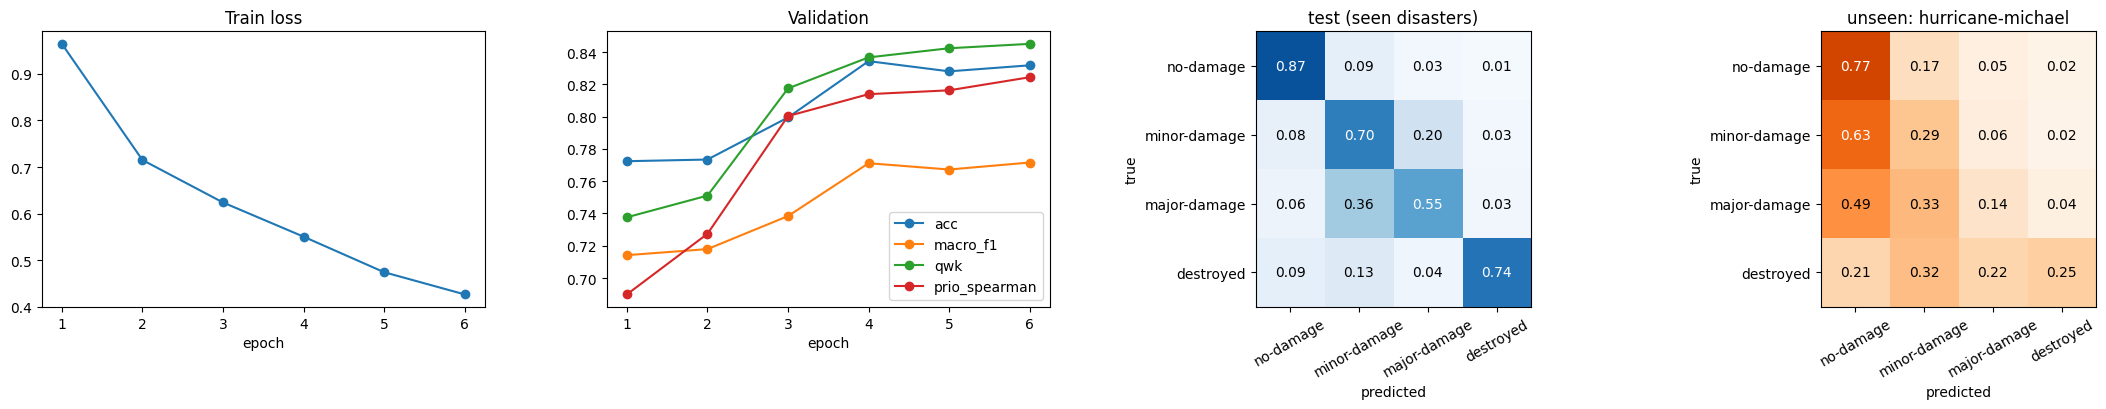

In [9]:
# ---- Train, then evaluate on seen-disaster test set and on the UNSEEN disaster ----
model, hist = train_model(CFG)

EVAL = {"test (seen disasters)": test_df, f"unseen: {UNSEEN_DISASTER}": unseen_df}
res = {k: predict(model, make_loader(d, False), tta=True) for k, d in EVAL.items()}
table = pd.DataFrame({k: metrics(o) for k, o in res.items()}).T
print("\n" + table.round(3).to_string())
o = res[f"unseen: {UNSEEN_DISASTER}"]
print(f"\nPer-class report on {UNSEEN_DISASTER}:")
print(classification_report(o["y"], o["probs"].argmax(1), target_names=list(CLASS_MAP), zero_division=0))

fig, ax = plt.subplots(1, 4, figsize=(22, 4.2))
ax[0].plot(hist.epoch, hist.train_loss, marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
for c in ("val_acc", "val_macro_f1", "val_qwk", "val_prio_spearman"): ax[1].plot(hist.epoch, hist[c], marker="o", label=c[4:])
ax[1].legend(); ax[1].set_title("Validation"); ax[1].set_xlabel("epoch")
for a, (k, o_), cmap in zip(ax[2:], res.items(), ("Blues", "Oranges")):
    cm = confusion_matrix(o_["y"], o_["probs"].argmax(1), labels=range(NUM_CLASSES), normalize="true")
    a.imshow(cm, cmap=cmap, vmin=0, vmax=1); a.set_title(k); a.set_xlabel("predicted"); a.set_ylabel("true")
    a.set_xticks(range(NUM_CLASSES)); a.set_xticklabels(list(CLASS_MAP), rotation=30); a.set_yticks(range(NUM_CLASSES)); a.set_yticklabels(list(CLASS_MAP))
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES): a.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > .5 else "black")
plt.tight_layout(); plt.show()
torch.save(model.state_dict(), "best_model.pt"); hist.to_csv("training_history.csv", index=False)

In [10]:
# ---- Score every held-out building: damage class, learned priority, tiers, uncertainty flag, location ranking ----
score_df = pd.concat([test_df.assign(split="test"), unseen_df.assign(split="unseen")]).dropna(subset=["lat", "lon"]).reset_index(drop=True)
o = predict(model, make_loader(score_df, False), tta=True)
probs = o["probs"]
score_df["pred_label"] = probs.argmax(1); score_df["pred_label_name"] = score_df.pred_label.map(IDX_TO_CLASS)
score_df["pred_confidence"] = probs.max(1)
score_df["entropy"] = -(probs * np.log(probs + 1e-9)).sum(1) / np.log(NUM_CLASSES)
score_df["priority_score"] = o["prio"]                                            # LEARNED priority (deep-learning head)

q = score_df.priority_score.rank(pct=True)
score_df["priority_tier"] = np.select([q >= .95, q >= .80, q >= .50], ["Critical", "High", "Medium"], "Low")
score_df["needs_human_review"] = (score_df.entropy > 0.75) & (q >= .80)           # high priority but model unsure -> person checks
score_df = score_df.sort_values("priority_score", ascending=False).reset_index(drop=True)
score_df["priority_rank"] = score_df.index + 1
score_df.to_csv("priority_scores.csv", index=False)
print(f"Scored {len(score_df):,} buildings | tiers: {score_df.priority_tier.value_counts().to_dict()} | flagged for review: {int(score_df.needs_human_review.sum())}")
print(score_df[["priority_rank", "uid", "disaster_type", "split", "pred_label_name", "pred_confidence", "priority_score", "priority_tier"]].head(10).to_string())

# LOCATION-level ranking (what response teams dispatch to): one row per scene / area
loc = (score_df.assign(severe=score_df.pred_label >= 2).groupby("scene_id").agg(
        disaster=("disaster_type", "first"), lat=("lat", "mean"), lon=("lon", "mean"), n_buildings=("uid", "count"),
        mean_priority=("priority_score", "mean"), max_priority=("priority_score", "max"), pct_severe=("severe", "mean"),
        n_flagged=("needs_human_review", "sum")).reset_index())
loc = loc[loc.n_buildings >= 5].sort_values("mean_priority", ascending=False).reset_index(drop=True)
loc["location_rank"] = loc.index + 1
loc.to_csv("location_priority.csv", index=False)
print(f"\nTop affected LOCATIONS ({len(loc)} areas with >=5 buildings):")
print(loc.head(10).round(3).to_string())

  0%|          | 0/347 [00:00<?, ?it/s]

Scored 22,147 buildings | tiers: {'Low': 11076, 'Medium': 6639, 'High': 3324, 'Critical': 1108} | flagged for review: 1165
   priority_rank                                   uid        disaster_type split pred_label_name  pred_confidence  priority_score priority_tier
0              1  d8b07fc1-5cc4-47f4-8469-cbfa71846587         palu-tsunami  test       destroyed         0.934252        0.897135      Critical
1              2  835cac83-1854-4d65-b451-5ef6190dfa0c         palu-tsunami  test       destroyed         0.955108        0.896322      Critical
2              3  687eaedd-222a-4a14-a544-10cf709a52d1         palu-tsunami  test       destroyed         0.975688        0.891113      Critical
3              4  8fa909da-f889-44a2-922e-1cd37ab2f6a0         palu-tsunami  test       destroyed         0.849157        0.890462      Critical
4              5  861ba96f-3ae4-4c40-9299-922041c9392f         palu-tsunami  test       destroyed         0.968308        0.888184      Critical
5      

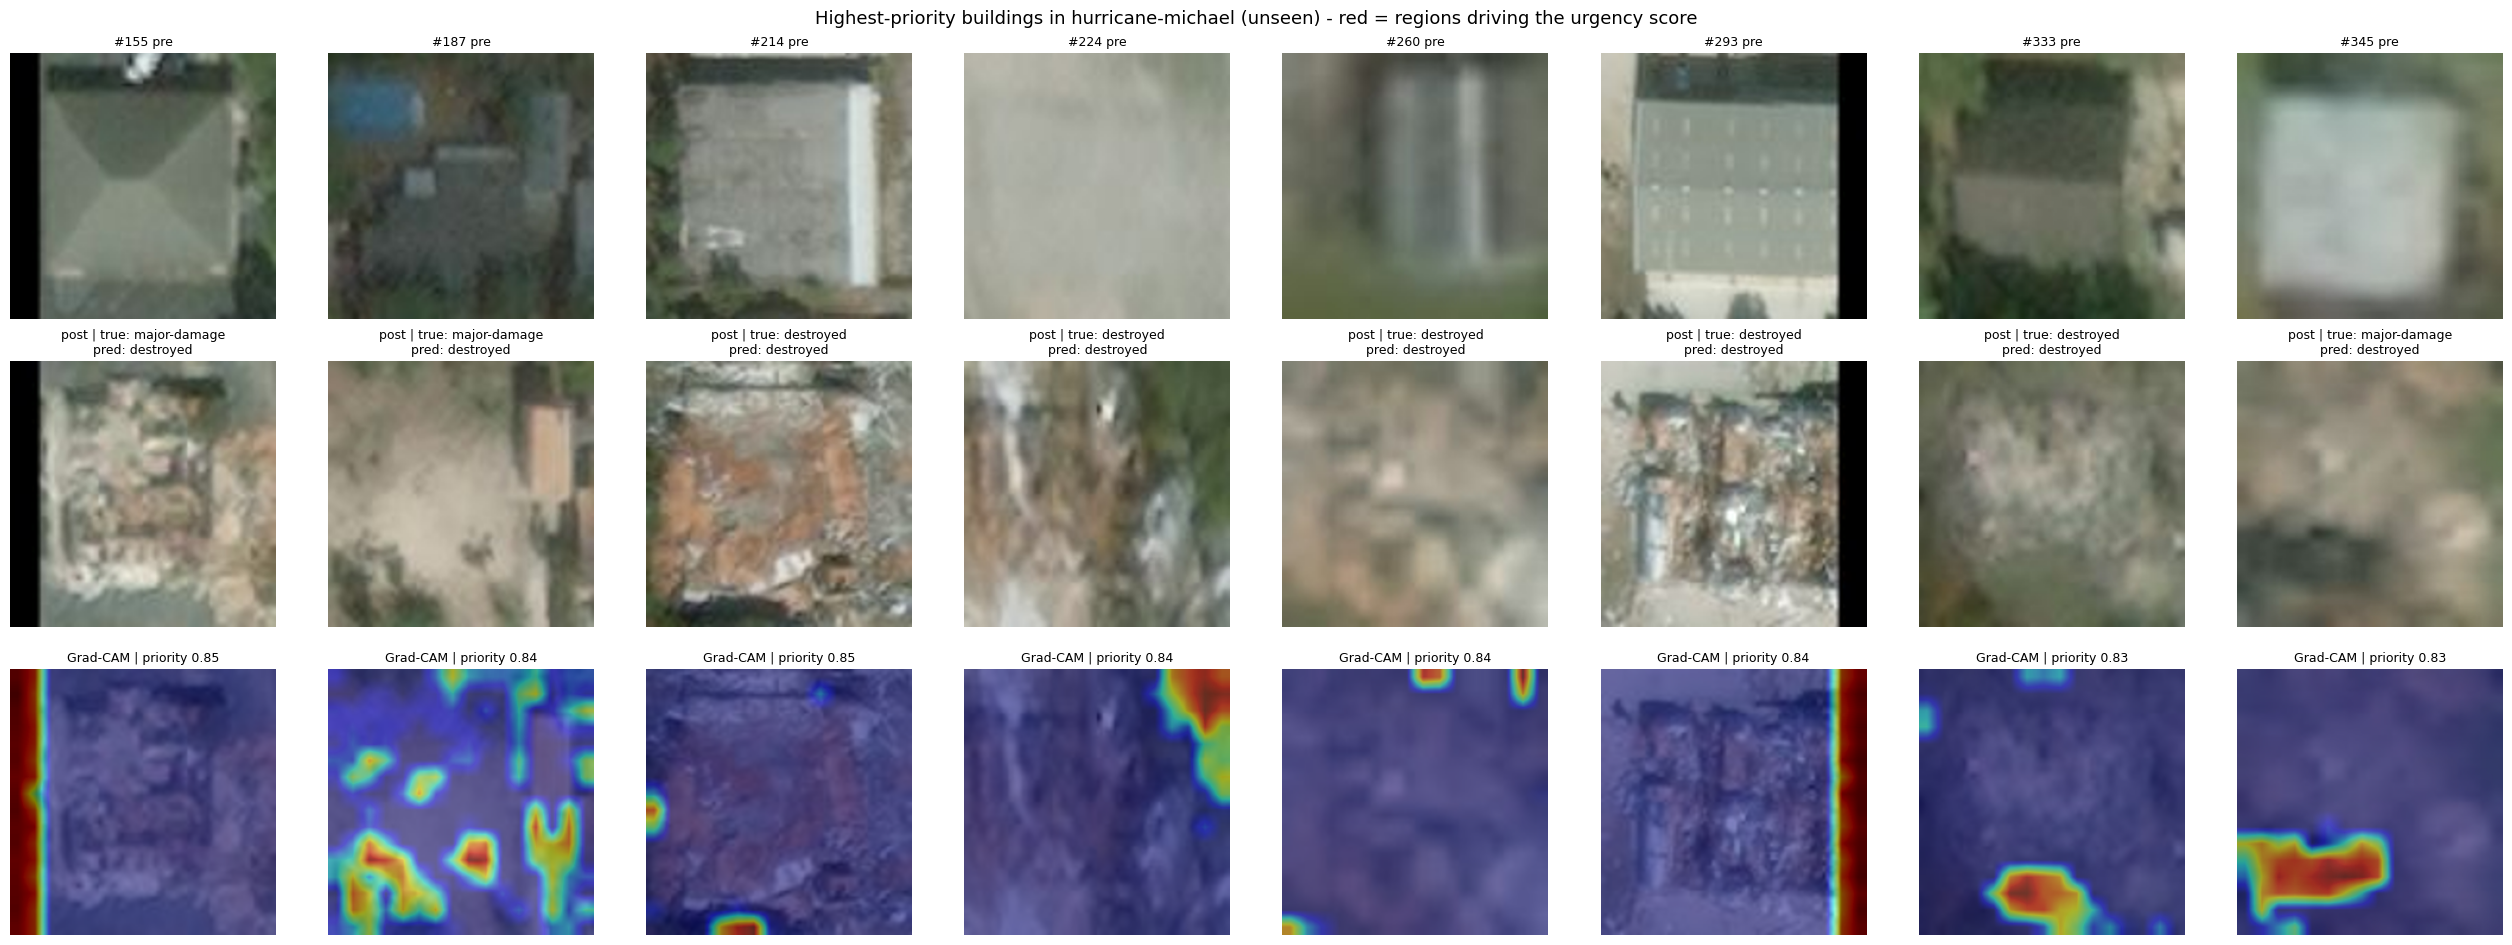

In [11]:
# ---- Grad-CAM: which part of the building / area drives the urgency score? ----
denorm = lambda t: (t.cpu() * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()
overlay = lambda img, cam, a=0.5: (1 - a) * img + a * mcm.jet(cam)[..., :3]

def load_pair(row):
    return BuildingDamageDataset(pd.DataFrame([row]), CFG["img_size"], False)[0]          # pre, post, y, ctx, tgt

def gradcam(model, pre, post, ctx):
    """Grad-CAM on the last transformer block for the priority output; returns CAM of the POST image, predicted class, priority."""
    store = {}
    h = model.vit.blocks[-1].register_forward_hook(lambda mod, i, out: store.__setitem__("a", out))
    try:
        model.eval()
        with torch.enable_grad():
            logits, prio = model(pre[None].to(DEVICE), post[None].to(DEVICE), ctx[None].to(DEVICE))
            grad = torch.autograd.grad(prio.sum(), store["a"])[0]
    finally:
        h.remove()
    act, grad = store["a"].detach().float(), grad.float()
    g = int(round((act.size(1) - model.npt) ** 0.5))
    a, gr = act[1, model.npt:], grad[1, model.npt:]                                        # index 1 = post image of the Siamese batch
    cam = F.relu((a * gr.mean(0, keepdim=True)).sum(-1)).reshape(1, 1, g, g)
    cam = F.interpolate(cam, size=(CFG["img_size"],) * 2, mode="bilinear", align_corners=False)[0, 0]
    cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-9)).cpu().numpy()
    return cam, int(logits.argmax(1)), float(prio.detach())

top = score_df[score_df.split == "unseen"].head(8)
fig, axes = plt.subplots(3, len(top), figsize=(3.2 * len(top), 9.6))
for j, (_, r) in enumerate(top.iterrows()):
    pre, post, y, ctx, tgt = load_pair(r)
    cam, cls, prio = gradcam(model, pre, post, ctx)
    axes[0, j].imshow(denorm(pre));  axes[0, j].set_title(f"#{int(r.priority_rank)} pre", fontsize=9)
    axes[1, j].imshow(denorm(post)); axes[1, j].set_title(f"post | true: {IDX_TO_CLASS[y]}\npred: {IDX_TO_CLASS[cls]}", fontsize=9)
    axes[2, j].imshow(overlay(denorm(post), cam)); axes[2, j].set_title(f"Grad-CAM | priority {prio:.2f}", fontsize=9)
    for a in axes[:, j]: a.axis("off")
plt.suptitle(f"Highest-priority buildings in {UNSEEN_DISASTER} (unseen) - red = regions driving the urgency score", fontsize=13)
plt.tight_layout(); plt.savefig("gradcam_top_priority.png", dpi=120, bbox_inches="tight"); plt.show()

Saved priority_map.html



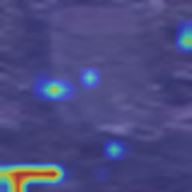
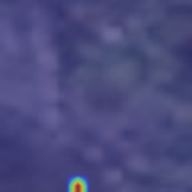
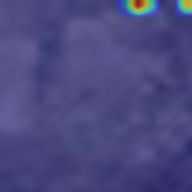
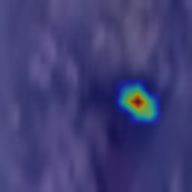
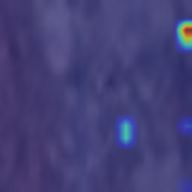
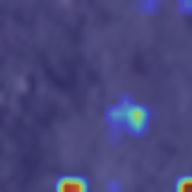
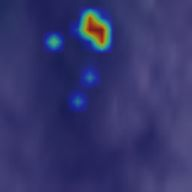
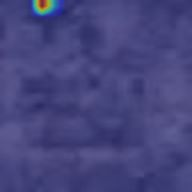
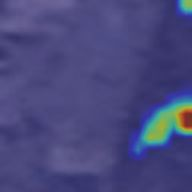
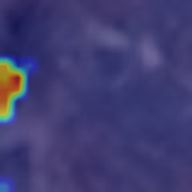
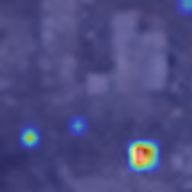
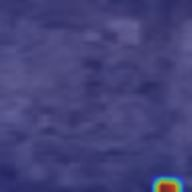
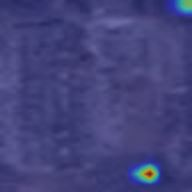
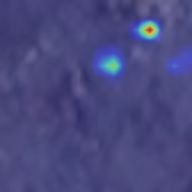
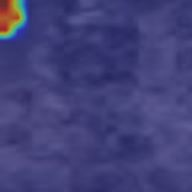
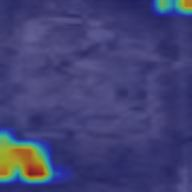
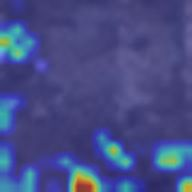
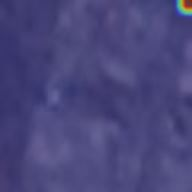
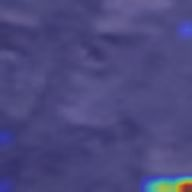
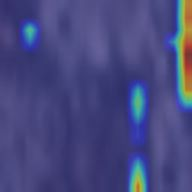
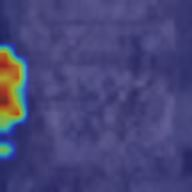
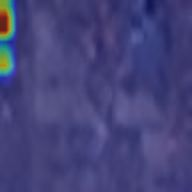
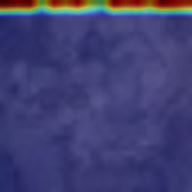
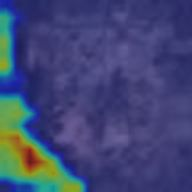
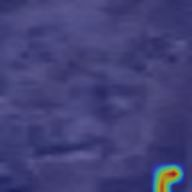
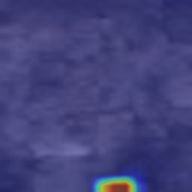
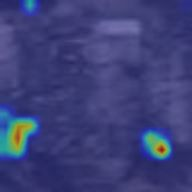
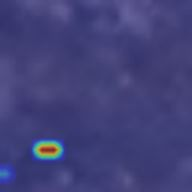
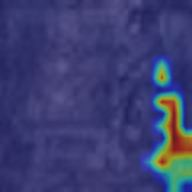
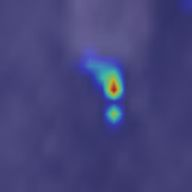

In [12]:
# ---- Priority map: heat layer + ranked areas + ranked buildings (top-30 popups carry Grad-CAM) ----
import folium
from folium.plugins import MarkerCluster, HeatMap

TIER_COLOR = {"Critical": "darkred", "High": "orange", "Medium": "gold", "Low": "green"}
N_CAM, N_MAP = 30, 2000

def cam_popup(row):
    pre, post, _, ctx, _ = load_pair(row)
    cam, _, _ = gradcam(model, pre, post, ctx)
    buf = io.BytesIO(); Image.fromarray((overlay(denorm(post), cam) * 255).astype(np.uint8)).resize((192, 192)).save(buf, format="JPEG", quality=80)
    return base64.b64encode(buf.getvalue()).decode()

map_df = score_df.head(N_MAP)
m = folium.Map(location=[map_df.lat.mean(), map_df.lon.mean()], zoom_start=5, tiles="OpenStreetMap")

heat = folium.FeatureGroup("Priority heat layer", show=True)
HeatMap(score_df[["lat", "lon", "priority_score"]].values.tolist(), radius=14, blur=18, min_opacity=0.25).add_to(heat); heat.add_to(m)

areas = folium.FeatureGroup("Ranked areas", show=True)
for _, r in loc.head(300).iterrows():
    folium.CircleMarker([r.lat, r.lon], radius=6 + 18 * r.mean_priority, color="#4c1d95", fill=True, fill_opacity=0.25, weight=2,
        popup=folium.Popup(f"<b>Area #{r.location_rank}</b> ({r.disaster})<br>{int(r.n_buildings)} buildings<br>mean priority {r.mean_priority:.3f}<br>"
                           f"severe/destroyed: {r.pct_severe:.0%}<br>flagged for review: {int(r.n_flagged)}", max_width=250)).add_to(areas)
areas.add_to(m)

blds = folium.FeatureGroup("Ranked buildings (top 2000)", show=True); cluster = MarkerCluster().add_to(blds)
for k, (_, r) in enumerate(map_df.iterrows()):
    html = (f"<b>Rank #{r.priority_rank}</b> - {r.priority_tier}<br>{r.disaster_type}<br>Damage: {r.pred_label_name} (conf {r.pred_confidence:.2f})<br>"
            f"Priority: {r.priority_score:.3f}" + ("<br><b>&#9888; review manually</b>" if r.needs_human_review else ""))
    if k < N_CAM: html += f'<br><img src="data:image/jpeg;base64,{cam_popup(r)}" width="192"><br><i>Grad-CAM: red = drives urgency</i>'
    folium.CircleMarker([r.lat, r.lon], radius=7 if r.needs_human_review else 5, color=TIER_COLOR[r.priority_tier], fill=True, fill_opacity=.8,
                        weight=3 if r.needs_human_review else 1, popup=folium.Popup(html, max_width=260)).add_to(cluster)
blds.add_to(m)

m.get_root().html.add_child(folium.Element("""<div style="position:fixed;bottom:30px;left:30px;z-index:1000;background:white;padding:10px;border:2px solid grey;border-radius:5px;font-size:13px;">
<b>Priority tier</b><br><span style="color:darkred">&#9679;</span> Critical (top 5%)<br><span style="color:orange">&#9679;</span> High (next 15%)<br>
<span style="color:gold">&#9679;</span> Medium (next 30%)<br><span style="color:green">&#9679;</span> Low<br>Thick outline = uncertain, review<br>Purple circle = ranked area</div>"""))
folium.LayerControl(collapsed=False).add_to(m)
m.save("priority_map.html"); print("Saved priority_map.html")
m

In [13]:
# ---- Download everything as one zip ----
from google.colab import files
os.makedirs("results", exist_ok=True)
for f in ["best_model.pt", "training_history.csv", "priority_scores.csv", "location_priority.csv", "priority_map.html", "gradcam_top_priority.png"]:
    shutil.copy(f, "results/")
shutil.make_archive("results", "zip", "results")
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>